# 26 — Time-varying national local risk prices across countries

Audit the local conditioners **before estimation**, then allow the national local price to vary for
**Poland, Czechia, Romania, Sweden and Hungary**, in **USD and EUR**, under **scalar and diagonal
BEKK**. Keep the frozen **October 2014–September 2026 (144 months)** sample and **Python 3 (base)**.

Keep notebook 25's world and FX conditioning designs, corrected five-series priced means and zero
alphas. World/FX/covariance parameters are jointly re-estimated; the **US local price stays constant**.
Compare 20 new systems with 20 verified constant-national-local-price references. No fetching,
installation, kernel changes, revised observations or changes to earlier research outputs.

In [1]:
# Fixed common sample; adjustable numerical and diagnostic controls.
START_DYNAMICS = [(0.05, 0.90), (0.10, 0.70)]
MAX_ITER = 2500
TEST_LAGS = 12
HAC_LAGS = (0, 3, 6, 12)
REUSE_FITS = True
MODEL_VERSION = "regional_time_varying_local_priced_means_v1"
WORLD_INSTRUMENTS = ["short_rate_change_lag1_pp", "term_spread_change_lag1_pp", "credit_spread_lag1_pp"]
NATIONAL_INFLATION_FORM = "change"  # locked national-FX design from notebook 25
OTHER_INFLATION_FORM = "level"      # locked other-FX design from notebook 25
INCLUDE_REGIME = True  # locked FX setting
LOCAL_INFLATION_FORM = "change"  # primary; "level" creates a separate local-only configuration
INCLUDE_LOCAL_REGIME = True
PREVIOUS_MANIFEST_SHA = "06746ac3266e6b3eb37301c449d1e03ac36ceb22ccd6bb1cea1f54d8430534d1"
LOCK_HASHES = {
    "regional_dataset_inputs.json": "0ceeef569dc4513d8534faf346509b22245db7ebff63abeb77044fc1474be208",
    "research_synthesis_inputs.json": "4fc2f36215746dd0ad0fef3ac41d8953f4abc6f1a3a36b526813437a26f081ee",
}

from pathlib import Path
from io import BytesIO
import hashlib, importlib, importlib.metadata, json, os, platform, sys
ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2
from packaging.version import Version
versions = {p: importlib.metadata.version(p) for p in
            ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "ipykernel"]}
if Version(versions["statsmodels"]) < Version("0.15.0"):
    raise RuntimeError("Use the base environment already used for notebooks 20–22 (statsmodels 0.15.0 or later).")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__ != versions["statsmodels"]:
    raise RuntimeError("Restart the existing base kernel to discard stale statsmodels imports.")
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown
import pricing_robustness as core
importlib.reload(core)
import regional_local_pricing as engine
importlib.reload(engine)

NAMES = {"PL": "Poland", "CZ": "Czechia", "RO": "Romania", "SE": "Sweden", "HU": "Hungary"}
LOCAL_CURRENCIES = {"PL": "PLN", "CZ": "CZK", "RO": "RON", "SE": "SEK", "HU": "HUF"}
COUNTRY_ORDER, CURRENCIES, COVARIANCES = ["HU", "PL", "CZ", "RO", "SE"], ["USD", "EUR"], ["scalar", "diagonal"]
ASSETS = ["World", "US", "National", "National FX", "Other FX"]
COLORS = {"PL": "#285f9e", "CZ": "#2a8a70", "RO": "#9469ad", "SE": "#b77d13", "HU": "#c4483b"}
PREVIOUS = ROOT/"output"/"25_regional_time_varying_currency"/"2014-10_2026-09"/"fx_a9208202"
WORLD_PREVIOUS = ROOT/"output"/"24_regional_time_varying_world"/"2014-10_2026-09"/"z_c1170c40"
CANDIDATES = ["short_rate_change_lag1_pp", "term_spread_change_lag1_pp", "credit_spread_lag1_pp"]
assert NATIONAL_INFLATION_FORM in ["change", "level"] and OTHER_INFLATION_FORM in ["change", "level"]
fx_spec = {"world_instruments": WORLD_INSTRUMENTS, "national_inflation": NATIONAL_INFLATION_FORM,
        "other_inflation": OTHER_INFLATION_FORM, "include_varying_regime": INCLUDE_REGIME,
        "world_design_sha256": "b59be89293797cc8740eb29a35f81f742818a6d839222594f0162c2309f18acf"}
assert LOCAL_INFLATION_FORM in ["change", "level"]
spec = {"local_inflation": LOCAL_INFLATION_FORM, "include_varying_local_regime": INCLUDE_LOCAL_REGIME,
        "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA}
instrument_id = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:8]
OUT = ROOT/"output"/"26_regional_time_varying_local"/"2014-10_2026-09"/f"local_{instrument_id}"
OUT.mkdir(parents=True, exist_ok=True)
def sha(raw): return hashlib.sha256(raw).hexdigest()
engine_hashes = {name: sha((ROOT/name).read_bytes()) for name in
    ["regional_local_pricing.py", "regional_fx_price_variation.py", "regional_world_pricing.py", "regional_currency_pricing.py", "pricing_robustness.py", "regional_pricing_baseline.py", "regional_covariance_sensitivity.py"]}
assert 2 <= TEST_LAGS <= 24 and tuple(HAC_LAGS) == (0, 3, 6, 12)
assert all(a > 0 and b > 0 and a+b < 1 for a, b in START_DYNAMICS)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .18})
pd.set_option("display.max_columns", 14)
print("Python:", sys.executable)
print("Packages:", versions)
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.sm_exceptions import InterpolationWarning
print("Local-price engine SHA-256:", engine_hashes["regional_local_pricing.py"])

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8', 'ipykernel': '7.2.0'}
Local-price engine SHA-256: f19326824d977a250770428f9951223e8219d5fdebb63b07aeff9e462757b2fb


## 1. Verify the frozen sample and upstream outputs

Verify notebook 25's pinned manifest, protected input/output hashes and engines. Keep all ten
five-series datasets, their USD/EUR conversion identities, the same 144 months and the matched
Hungarian reference. Re-filter the 20 saved conditional-world/FX, constant-local models before use.
The two investor perspectives are dependent numeraires of the same observations.

In [2]:
def verify_inputs():
    raw = (PREVIOUS/"estimation_manifest.json").read_bytes()
    if sha(raw) != PREVIOUS_MANIFEST_SHA: raise ValueError("Notebook-25 manifest changed.")
    previous = json.loads(raw)
    assert previous["input_locks"] == LOCK_HASHES
    assert (previous["first"], previous["last"], previous["observations_per_fit"]) == ("2014-10", "2026-09", 144)
    expected = previous["input_file_hashes"].copy()
    for name, checksum in previous["outputs"].items():
        expected[(PREVIOUS/name).relative_to(ROOT).as_posix()] = checksum
    expected[(PREVIOUS/"estimation_manifest.json").relative_to(ROOT).as_posix()] = PREVIOUS_MANIFEST_SHA
    expected.update(previous["engines"])
    locks = {}
    for name, checksum in LOCK_HASHES.items():
        content = (ROOT/name).read_bytes()
        if sha(content) != checksum: raise ValueError(f"Changed input lock: {name}")
        locks[name] = json.loads(content)
    for path, checksum in expected.items():
        if sha((ROOT/path).read_bytes()) != checksum: raise ValueError(f"Changed frozen input: {path}")
    regional = locks["regional_dataset_inputs.json"]
    assert sha((ROOT/regional["root"]/"manifest.json").read_bytes()) == regional["manifest_sha256"]
    return locks, expected

locks, input_hashes = verify_inputs()
regional = locks["regional_dataset_inputs.json"]
assert (regional["common_start"], regional["common_end"], regional["common_months"]) == ("2014-10", "2026-09", 144)
months = pd.period_range("2014-10", "2026-09", freq="M", name="month")
frames, samples, scales, source_hashes, audit_rows = {}, {}, {}, {}, []
for country in COUNTRY_ORDER:
    for currency in CURRENCIES:
        path = ROOT/regional["root"]/"common"/f"{country}_{currency}.csv"
        raw = path.read_bytes()
        assert sha(raw) == input_hashes[path.relative_to(ROOT).as_posix()]
        d = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
        d.index = pd.PeriodIndex(d.index, freq="M", name="month")
        assert d.index.equals(months) and np.isfinite(d.to_numpy()).all() and d.flag_known_index_backcast.sum() == 0
        for asset in ["world", "us", "local"]:
            np.testing.assert_allclose(d[f"rx_{asset}"], d[f"r_{asset}"]-d.rf, atol=1e-12, rtol=0)
        y = d[["rx_world", "rx_us", "rx_local", "fx_local", "fx_other"]].to_numpy()*100
        scale = y.std(axis=0, ddof=1)
        correlation = np.cov(y, rowvar=False)/np.outer(scale, scale)
        assert (scale > 0).all() and np.linalg.eigvalsh(correlation).min() > 0 and np.linalg.matrix_rank(y-y.mean(axis=0)) == 5
        key = (country, currency)
        frames[key], samples[key], scales[key], source_hashes[key] = d, y, scale, sha(raw)
        np.testing.assert_array_equal(y[:, [0, 1, 4]], samples[("HU", currency)][:, [0, 1, 4]])
        audit_rows.append({"country": country, "name": NAMES[country], "perspective": currency,
            "first": str(months[0]), "last": str(months[-1]), "months": len(y), "rank": 5,
            "min_correlation_eigenvalue": np.linalg.eigvalsh(correlation).min(), "correlation_condition": np.linalg.cond(correlation),
            "national_FX_sd_pp": scale[3], "national_FX_currency": LOCAL_CURRENCIES[country],
            "other_FX_currency": "EUR" if currency == "USD" else "USD"})
transform = np.eye(5)
transform[:3, 4], transform[3, 4], transform[4, 4] = -1., -1., -1.
for country in COUNTRY_ORDER:
    converted = samples[(country, "USD")]@transform.T
    converted[:, :3] += ((frames[(country, "USD")].rf-frames[(country, "EUR")].rf)*100).to_numpy()[:, None]
    np.testing.assert_allclose(converted, samples[(country, "EUR")], atol=1e-10, rtol=0)
input_audit = pd.DataFrame(audit_rows)
display(input_audit.set_index(["name", "perspective"])[["months", "rank", "correlation_condition", "national_FX_sd_pp", "other_FX_currency"]].round(4))
print("Verified", len(input_hashes), "protected files and all ten five-series input systems.")

months  rank  correlation_condition  national_FX_sd_pp  \
name    perspective                                                           
Hungary USD             144     5               177.8975             3.0207   
        EUR             144     5               123.6042             1.7874   
Poland  USD             144     5               196.7334             2.9611   
        EUR             144     5               135.7310             1.4953   
Czechia USD             144     5               218.7463             2.6464   
        EUR             144     5               152.3439             1.1305   
Romania USD             144     5               168.0376             2.1759   
        EUR             144     5               110.8968             0.5283   
Sweden  USD             144     5               242.4797             2.9674   
        EUR             144     5               174.9449             1.7097   

                    other_FX_currency  
name    perspective                    
Hungary USD                       EUR  
        EUR                       USD  
Poland  USD                       EUR  
        EUR                       USD  
Czechia USD                       EUR  
        EUR                       USD  
Romania USD                       EUR  
        EUR                       USD  
Sweden  USD                       EUR  
        EUR                       USD

Verified 1241 protected files and all ten five-series input systems.


## 2. Audit local instruments, timing and rank first

The primary local design is a constant, the **two-month-lagged change in investor-minus-national
annual inflation**, and a varying existing regime indicator. It follows the earlier Hungarian local
extension. Do not add global financial predictors to the local price. Audit both gap **changes and
levels**, keeping the default predeclared rather than choosing it from pricing p-values. A local-only
level setting creates a separate configuration; it leaves world/FX designs fixed.

Reconstruct inflation from frozen raw US CPI/European HICP, with all changes and lags formed
**before sample trimming**. Preserve the inherited one-month carry of the US annual inflation
rate, without filling CPI levels, national HICP or market data. The primary USD local conditioner
uses that carried value in **December 2025 and January 2026**; EUR local conditioning does not.
The two-month lag approximates publication availability; these are historical, not real-time vintages.
CPI/HICP concept differences remain a limitation.

Only Czechia's floor indicator varies (known December 2013–April 2017); constant PL/HU indicators
and RO/SE zero placeholders are excluded. The placeholders do not classify exchange-rate regimes.
Do not run unit-root tests on binary indicators. Audit support, persistence, ADF/KPSS, VIF, rank,
conditioning, extremes and leverage. Retain all 144 months. Center/scale on this estimation window
(sample SD, ddof=1); this normalization is not a forecast exercise.

Reconstruct and verify the **unchanged world and both FX designs** against notebook 25. Shared
inflation/regime variables across FX/local prices are allowed: they are joint-QML conditioning
variables, not excluded IV instruments. A fixed-covariance mean-loading rank check below is a
preliminary screen; joint curvature and SE stability still govern inference after estimation.

used_in_local  lag1_correlation  \
country perspective instrument                                         
HU      USD         national_level           False            0.9834   
                    national_change           True            0.7581   
        EUR         national_level           False            0.9791   
                    national_change           True            0.5619   
PL      USD         national_level           False            0.9810   
                    national_change           True            0.4913   
        EUR         national_level           False            0.9783   
                    national_change           True            0.2775   
CZ      USD         national_level           False            0.9696   
                    national_change           True            0.1929   
        EUR         national_level           False            0.9456   
                    national_change           True            0.0389   
RO      USD         national_level           False            0.9745   
                    national_change           True            0.2306   
        EUR         national_level           False            0.9680   
                    national_change           True            0.0366   
SE      USD         national_level           False            0.9132   
                    national_change           True            0.0764   
        EUR         national_level           False            0.7413   
                    national_change           True           -0.1906   

                                     ADF_p_raw KPSS_p_report  
country perspective instrument                                
HU      USD         national_level      0.0005      0.098254  
                    national_change     0.0042         >=0.1  
        EUR         national_level      0.6173      0.069291  
                    national_change     0.0008         >=0.1  
PL      USD         national_level      0.5830      0.024662  
                    national_change     0.0000         >=0.1  
        EUR         national_level      0.6096        <=0.01  
                    national_change     0.0031         >=0.1  
CZ      USD         national_level      0.2321         >=0.1  
                    national_change     0.0002         >=0.1  
        EUR         national_level      0.2169         >=0.1  
                    national_change     0.0084         >=0.1  
RO      USD         national_level      0.3992        <=0.01  
                    national_change     0.0032         >=0.1  
        EUR         national_level      0.6865        <=0.01  
                    national_change     0.0000         >=0.1  
SE      USD         national_level      0.0757         >=0.1  
                    national_change     0.0000         >=0.1  
        EUR         national_level      0.0441      0.040874  
                    national_change     0.0000         >=0.1

rank  columns  condition_number  max_leverage
country perspective                                               
HU      USD             2        2            1.0035        0.1693
        EUR             2        2            1.0035        0.1487
PL      USD             2        2            1.0035        0.0852
        EUR             2        2            1.0035        0.0836
CZ      USD             3        3            1.0329        0.2521
        EUR             3        3            1.0195        0.2452
RO      USD             2        2            1.0035        0.1181
        EUR             2        2            1.0035        0.1080
SE      USD             2        2            1.0035        0.1153
        EUR             2        2            1.0035        0.1010

factor     VIF
country perspective instrument                     
HU      USD         national_change       L  1.0000
        EUR         national_change       L  1.0000
PL      USD         national_change       L  1.0000
        EUR         national_change       L  1.0000
CZ      USD         national_change       L  1.0010
                    regime_indicator      L  1.0010
        EUR         national_change       L  1.0004
                    regime_indicator      L  1.0004
RO      USD         national_change       L  1.0000
        EUR         national_change       L  1.0000
SE      USD         national_change       L  1.0000
        EUR         national_change       L  1.0000

zeros  ones  used_in_local                   reason
country perspective                                                     
HU      USD              0   144          False       constant; excluded
        EUR              0   144          False       constant; excluded
PL      USD              0   144          False       constant; excluded
        EUR              0   144          False       constant; excluded
CZ      USD            113    31           True  varying floor indicator
        EUR            113    31           True  varying floor indicator
RO      USD            144     0          False       constant; excluded
        EUR            144     0          False       constant; excluded
SE      USD            144     0          False       constant; excluded
        EUR            144     0          False       constant; excluded

,,flagged_months
country,perspective,
CZ,USD,"2025-12, 2026-01"
HU,USD,"2025-12, 2026-01"
PL,USD,"2025-12, 2026-01"
RO,USD,"2025-12, 2026-01"
SE,USD,"2025-12, 2026-01"


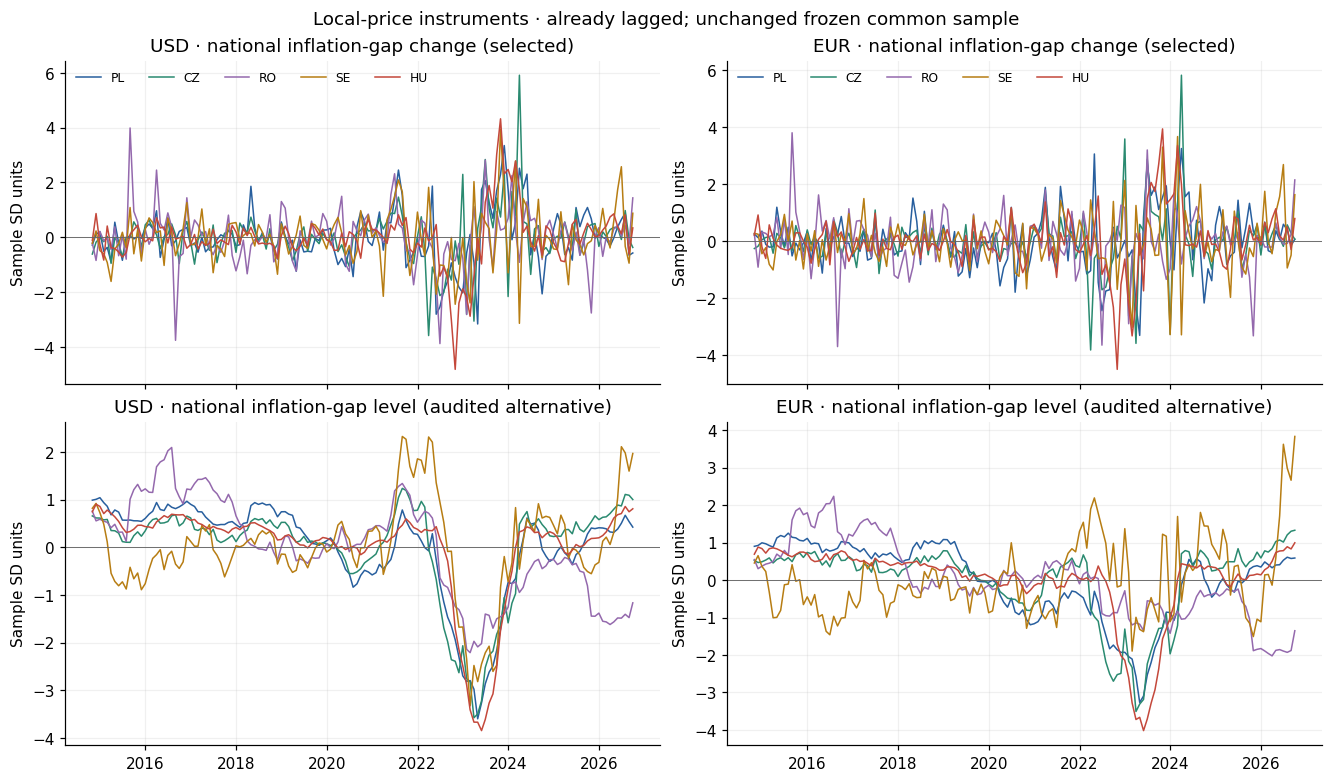

Local timing/rank audit passed; all 30 upstream world/FX designs are byte-identical. Only varying regime columns retained; gap persistence and inflation carry stay explicit.


In [3]:
upstream = json.loads((PREVIOUS/"estimation_manifest.json").read_text())
assert upstream["spec"] == fx_spec
old = json.loads((WORLD_PREVIOUS/"estimation_manifest.json").read_text())
assert old["world_instruments"] == WORLD_INSTRUMENTS
world_frame = pd.read_csv(WORLD_PREVIOUS/"conditioning_design.csv", index_col=0, float_precision="round_trip")
Z = world_frame.to_numpy()
assert sha(Z.tobytes()) == fx_spec["world_design_sha256"] == old["conditioning_sha256"]
assert list(world_frame.columns) == ["constant"]+WORLD_INSTRUMENTS
assert pd.PeriodIndex(world_frame.index, freq="M").equals(months)
fred = pd.read_csv(ROOT/locks["research_synthesis_inputs.json"]["snapshot"]/"raw/fred.csv", index_col=0, float_precision="round_trip")
fred.index = pd.PeriodIndex(fred.index, freq="M")
assert fred.index.is_unique
fred = fred.reindex(pd.period_range(fred.index.min(), fred.index.max(), freq="M"))
rebuilt_global = pd.DataFrame({CANDIDATES[0]: fred.TB3MS.diff().shift(1),
    CANDIDATES[1]: (fred.GS10-fred.TB3MS).diff().shift(1), CANDIDATES[2]: (fred.BAA-fred.AAA).shift(1)}).loc[months]
for d in frames.values(): np.testing.assert_allclose(d[CANDIDATES], rebuilt_global, atol=1e-12, rtol=0)
np.testing.assert_allclose(Z[:, 1:], (rebuilt_global.to_numpy()-np.array([old["centres"][n] for n in WORLD_INSTRUMENTS]))/
    np.array([old["spreads_ddof1"][n] for n in WORLD_INSTRUMENTS]), atol=1e-12, rtol=0)

def hicp(path):
    j = json.loads(path.read_text()); flat = np.full(np.prod(j["size"]), np.nan)
    assert j["id"] == ["freq", "unit", "coicop18", "geo", "time"] and j["size"][:3] == [1, 1, 1]
    for pos, value in j["value"].items(): flat[int(pos)] = value
    values = flat.reshape(j["size"])[0, 0, 0]
    geo = j["dimension"]["geo"]["category"]["index"]
    time = j["dimension"]["time"]["category"]["index"]
    return pd.DataFrame({g: values[i] for g, i in geo.items()}, index=pd.PeriodIndex(sorted(time, key=time.get), freq="M"))
calendar = pd.period_range("1998-01", "2026-09", freq="M")
original_root = ROOT/locks["research_synthesis_inputs.json"]["snapshot"]
levels = pd.concat([hicp(original_root/"raw/eurostat_hicp.json"), hicp(ROOT/regional["root"]/"raw/national_hicp.json")], axis=1).reindex(calendar)
annual = levels.pct_change(12, fill_method=None)*100
us_raw = fred.CPIAUCNS.reindex(calendar).pct_change(12, fill_method=None)*100
us = us_raw.ffill(limit=1)
carried = us_raw.isna() & us.notna()
assert list(carried[carried].index.astype(str)) == ["2025-10"]
raw_candidates, flags, audit_rows, regime_rows = {}, {}, [], []
for key, d in frames.items():
    country, currency = key
    investor = us if currency == "USD" else annual.EA
    national_gap = investor-annual[country]
    other_gap = us-annual.EA if currency == "USD" else annual.EA-us
    raw = pd.DataFrame({"national_level": national_gap.shift(2), "national_change": national_gap.diff().shift(2),
        "other_level": other_gap.shift(2), "other_change": other_gap.diff().shift(2)}).loc[months]
    assert np.isfinite(raw.to_numpy()).all()
    for a, b in [("national_level", "inflation_gap_lag2_pp"), ("national_change", "inflation_gap_change_lag2_pp"), ("other_level", "other_fx_gap_lag2_pp")]:
        np.testing.assert_allclose(raw[a], d[b], atol=1e-12, rtol=0)
    level_flag = carried.shift(2, fill_value=False).loc[months]
    change_flag = (carried | carried.shift(1, fill_value=False)).shift(2, fill_value=False).loc[months]
    np.testing.assert_array_equal(level_flag, d.flag_us_inflation_carried_lag2.astype(bool))
    flags[key] = pd.DataFrame({"national_uses_carried_US": (change_flag if NATIONAL_INFLATION_FORM == "change" else level_flag) & (currency == "USD"),
        "other_uses_carried_US": change_flag if OTHER_INFLATION_FORM == "change" else level_flag,
        "local_uses_carried_US": (change_flag if LOCAL_INFLATION_FORM == "change" else level_flag) & (currency == "USD")}, index=months)
    regime = d.regime_indicator
    expected_regime = ((months >= "2013-12") & (months <= "2017-04")).astype(float) if country == "CZ" else np.full(len(months), float(country in ["HU", "PL"]))
    np.testing.assert_array_equal(regime, expected_regime)
    varying = regime.nunique() > 1
    regime_rows.append({"country": country, "perspective": currency, "ones": int(regime.sum()), "zeros": int((regime == 0).sum()),
        "used": bool(INCLUDE_REGIME and varying), "used_in_local": bool(INCLUDE_LOCAL_REGIME and varying), "reason": "varying floor indicator" if varying else "constant; excluded",
        "first_one": str(months[regime.to_numpy() == 1][0]) if regime.sum() else "", "last_one": str(months[regime.to_numpy() == 1][-1]) if regime.sum() else ""})
    raw_candidates[key] = raw
    for name in raw:
        v = raw[name]; a = adfuller(v, maxlag=12, regression="c", autolag="AIC", result_object=False)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", InterpolationWarning)
            k = kpss(v, regression="c", nlags="auto", result_object=False)
        bound = (">=" if k[1] >= .1 else "<=") if any(issubclass(w.category, InterpolationWarning) for w in caught) else ""
        audit_rows.append({"country": country, "perspective": currency, "instrument": name,
            "used": name in ["national_"+NATIONAL_INFLATION_FORM, "other_"+OTHER_INFLATION_FORM],
            "used_in_local": name == "national_"+LOCAL_INFLATION_FORM, "n": len(v), "missing": int(v.isna().sum()),
            "mean_pp": v.mean(), "sd_pp": v.std(ddof=1), "lag1_correlation": v.autocorr(), "ADF_stat": a[0], "ADF_p_raw": a[1],
            "ADF_lags": a[2], "KPSS_stat": k[0], "KPSS_p_report": f"{bound}{k[1]:.5g}", "KPSS_lags": k[2]})
audit, regimes = pd.DataFrame(audit_rows), pd.DataFrame(regime_rows)
designs, design_names, transforms, design_rows, vif_rows, leverage_rows, conditioning_rows, flag_rows, candidate_rows = {}, {}, [], [], [], [], [], [], []
for key, d in frames.items():
    country, currency = key; raw = raw_candidates[key]
    designs[key], design_names[key] = {"W": Z}, {"W": ["constant"]+WORLD_INSTRUMENTS}
    for factor, extra_name in [("H", "national_"+NATIONAL_INFLATION_FORM), ("O", "other_"+OTHER_INFLATION_FORM)]:
        extras = raw[[extra_name]].copy()
        if factor == "H" and INCLUDE_REGIME and d.regime_indicator.nunique() > 1: extras["regime_indicator"] = d.regime_indicator
        center, spread = extras.mean(), extras.std(ddof=1)
        assert spread.gt(0).all()
        designs[key][factor] = np.c_[Z, ((extras-center)/spread).to_numpy()]
        design_names[key][factor] = ["constant"]+WORLD_INSTRUMENTS+list(extras)
        transforms.extend({"country": country, "perspective": currency, "factor": factor, "instrument": n, "mean": center[n], "sd_ddof1": spread[n]} for n in extras)
    extras = raw[["national_"+LOCAL_INFLATION_FORM]].copy()
    if INCLUDE_LOCAL_REGIME and d.regime_indicator.nunique() > 1: extras["regime_indicator"] = d.regime_indicator
    center, spread = extras.mean(), extras.std(ddof=1)
    assert spread.gt(0).all()
    designs[key]["L"] = np.c_[np.ones(len(months)), ((extras-center)/spread).to_numpy()]
    design_names[key]["L"] = ["constant"]+list(extras)
    transforms.extend({"country": country, "perspective": currency, "factor": "L", "instrument": n, "mean": center[n], "sd_ddof1": spread[n]} for n in extras)
    for factor, D in designs[key].items():
        assert np.isfinite(D).all() and np.linalg.matrix_rank(D) == D.shape[1]
        np.testing.assert_allclose(D[:, 1:].mean(axis=0), 0, atol=1e-14, rtol=0)
        leverage = np.sum(np.linalg.qr(D, mode="reduced")[0]**2, axis=1)
        design_rows.append({"country": country, "perspective": currency, "factor": factor, "rank": np.linalg.matrix_rank(D), "columns": D.shape[1],
            "condition_number": np.linalg.cond(D), "max_leverage": leverage.max(), "max_leverage_month": str(months[leverage.argmax()]),
            "high_leverage_months": int((leverage > 2*D.shape[1]/len(months)).sum()), "design_sha256": sha(D.tobytes())})
        vif_rows.extend({"country": country, "perspective": currency, "factor": factor, "instrument": n,
            "VIF": variance_inflation_factor(D, j)} for j, n in enumerate(design_names[key][factor]) if j)
        leverage_rows.extend({"country": country, "perspective": currency, "factor": factor, "month": str(m), "leverage": leverage[t],
            "reference_2p_over_n": 2*D.shape[1]/len(months)} for t, m in enumerate(months))
        conditioning_rows.extend({"country": country, "perspective": currency, "factor": factor, "month": str(m),
            "instrument": n, "value": D[t, j]} for j, n in enumerate(design_names[key][factor]) for t, m in enumerate(months))
    flag_rows.extend({"country": country, "perspective": currency, "month": str(m), **flags[key].iloc[t].to_dict()} for t, m in enumerate(months))
    candidate_rows.extend({"country": country, "perspective": currency, "month": str(m), **raw.iloc[t].to_dict()} for t, m in enumerate(months))
transform_table, design_audit, vifs, leverages, conditioning, quality_flags, candidates = map(pd.DataFrame,
    [transforms, design_rows, vif_rows, leverage_rows, conditioning_rows, flag_rows, candidate_rows])
saved_conditioning = pd.read_csv(PREVIOUS/"conditioning_design.csv", float_precision="round_trip")
for key, D in designs.items():
    country, currency = key
    for factor in ["W", "H", "O"]:
        rows = saved_conditioning.query("country == @country and perspective == @currency and factor == @factor")
        recovered = np.column_stack([rows.loc[rows.instrument.eq(n), "value"].to_numpy() for n in design_names[key][factor]])
        np.testing.assert_array_equal(D[factor], recovered)
        expected_hash = next(r["design_sha256"] for r in upstream["designs"] if (r["country"], r["perspective"], r["factor"]) == (country, currency, factor))
        assert sha(D[factor].tobytes()) == expected_hash
figure_files = []
def save_plot(name):
    plt.savefig(OUT/name, dpi=170, bbox_inches="tight", metadata={"Software": "Regional local-price notebook 26"})
    figure_files.append(name); plt.show(); plt.close()
display(audit.query("instrument in ['national_change', 'national_level']").set_index(["country", "perspective", "instrument"])
    [["used_in_local", "lag1_correlation", "ADF_p_raw", "KPSS_p_report"]].round(4))
display(design_audit.query("factor == 'L'").set_index(["country", "perspective"])[["rank", "columns", "condition_number", "max_leverage"]].round(4))
display(vifs.query("factor == 'L'").set_index(["country", "perspective", "instrument"]).round(4))
display(regimes.set_index(["country", "perspective"])[["zeros", "ones", "used_in_local", "reason"]])
display(quality_flags.query("local_uses_carried_US").groupby(["country", "perspective"]).agg(flagged_months=("month", lambda s: ", ".join(s))))
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for row, form in enumerate(["change", "level"]):
    for col, currency in enumerate(CURRENCIES):
        ax = axes[row, col]
        for country in NAMES:
            values = raw_candidates[(country, currency)]["national_"+form]
            ax.plot(months.to_timestamp("M"), (values-values.mean())/values.std(ddof=1), color=COLORS[country], lw=1, label=country)
        ax.axhline(0, color="#666666", lw=.6)
        ax.set(title=f"{currency} · national inflation-gap {form}"+(" (selected)" if form == LOCAL_INFLATION_FORM else " (audited alternative)"), ylabel="Sample SD units")
        if row == 0: ax.legend(ncol=5, frameon=False, fontsize=8)
fig.suptitle("Local-price instruments · already lagged; unchanged frozen common sample")
save_plot("01_local_instruments.png")
print("Local timing/rank audit passed; all 30 upstream world/FX designs are byte-identical. Only varying regime columns retained; gap persistence and inflation carry stay explicit.")

## 3. Extend only the national local-price function

For country c and investor I, define g = investor inflation minus national inflation. The default is

$$\boxed{\lambda_{c,local,t}=b_{c,0}+b_{c,\pi}\widetilde{(g_{t-2}-g_{t-3})}
+b_{c,D}\widetilde D_t.}$$

The regime slope enters only where the known indicator varies (Czechia). Stored columns are
already lagged; do not lag them again. Centered regressors make the intercept the average fitted
local price; slopes measure its change per one sample SD. Prices are linear and unrestricted in sign.

$$\boxed{\mu_{c,t}=\lambda_{W,t}H_{cW,t}+\lambda_{FX,c,t}H_{c,FXc,t}
+\lambda_{FX,o,t}H_{c,FXo,t}+\lambda_{c,local,t}H_{cc,t}.}$$

The local component multiplies the **national equity's own conditional variance**, not an
orthogonalized residual variance. Other equations retain their corrected world/FX priced means;
the US equation also retains its constant US local price. Zero alphas, stationary innovation
initialization and scalar/diagonal covariance recursions remain unchanged.

Set the new local slopes to zero to nest notebook 25. Add **one local slope** for PL/RO/SE/HU,
**two for Czechia**: scalar 33→34 (CZ 34→36), diagonal 41→42 (CZ 42→44). Re-estimate all free
parameters jointly; the fixed-covariance loading screen is not a two-step estimator or proof of identification.

In [4]:
constant_fits, check_rows, loading_rows = {}, [], []
for key, y in samples.items():
    country, currency = key; D, scale = designs[key], scales[key]
    for covariance in COVARIANCES:
        record = json.loads((PREVIOUS/f"fit_{country}_{currency}_{covariance}_time_varying_fx.json").read_text())
        config = record["config"]
        assert (config["country"], config["perspective"], config["covariance"], config["source_sha256"]) == (country, currency, covariance, source_hashes[key])
        assert record["fingerprint"] == sha(json.dumps(config, sort_keys=True).encode()+y.tobytes()+b"".join(D[a].tobytes() for a in ["W", "H", "O"]))
        theta0 = np.asarray(record["theta"])
        base = engine.filter_model(theta0, y, D, scale, False, covariance)
        assert abs(base["losses"].mean()-record["mean_nll"]) < 1e-8
        assert np.abs(engine.projected_gradient(theta0, base["scores"].mean(axis=0), engine.bounds(D, False, covariance))).max() < 1e-4
        with np.load(PREVIOUS/f"parameters_{country}_{currency}_{covariance}_time_varying_fx.npz", allow_pickle=False) as saved:
            np.testing.assert_array_equal(theta0, saved["theta"])
            for field in ["H", "mu", "errors", "scores"]: np.testing.assert_allclose(base[field], saved[field], atol=1e-12, rtol=0)
        constant_fits[(*key, covariance)] = {"theta": theta0, "filter": base, "varying": False,
            "y": y, "scales": scale, "designs": D, "record": record}
        nested = engine.filter_model(engine.lift_constant_local(theta0, D), y, D, scale, True, covariance)
        for field in ["H", "mu", "errors", "losses"]: np.testing.assert_allclose(nested[field], base[field], atol=1e-12, rtol=0)
        indices = engine.price_indices(D, True)
        k = 5+sum(d.shape[1]-1 for d in D.values())
        M = np.zeros((len(y), 5, k))
        for label, factor in [("W", 0), ("H", 3), ("O", 4)]:
            M[:, :, indices[label]] = base["H"][:, :, factor, None]*D[label][:, None, :]
        M[:, 1, 1] = base["H"][:, 1, 1]
        M[:, 2, indices["L"]] = base["H"][:, 2, 2, None]*D["L"]
        flat = M.reshape(-1, k); norms = np.linalg.norm(flat, axis=0)
        assert (norms > 0).all()
        standardized = flat/norms
        rank, condition = np.linalg.matrix_rank(standardized), np.linalg.cond(standardized)
        assert rank == k and np.isfinite(condition)
        loading_rows.append({"country": country, "perspective": currency, "covariance": covariance,
            "rank": rank, "columns": k, "column_scaled_condition": condition})
        theta = engine.initial_theta(y, D, scale, True, covariance)
        ids = engine.price_indices(D, True)
        for label in ids: theta[ids[label][1:]] = np.linspace(.1, -.08, len(ids[label])-1)
        if covariance == "diagonal": theta[-10:] += np.linspace(-.1, .1, 10)
        sub = {a: v[:35] for a, v in D.items()}
        analytic = engine.objective(theta, y[:35], sub, scale, True, covariance)[1]
        numeric = engine.numerical_gradient(lambda t: engine.objective(t, y[:35], sub, scale, True, covariance)[0], theta)
        np.testing.assert_allclose(analytic, numeric, atol=5e-6, rtol=5e-5)
        probe = engine.filter_model(theta, y, D, scale, True, covariance)
        expected = probe["world_prices"][:, None]*probe["H"][:, :, 0]
        expected += probe["fx_prices"][:, 0, None]*probe["H"][:, :, 3]+probe["fx_prices"][:, 1, None]*probe["H"][:, :, 4]
        expected[:, 1] += probe["prices"][1]*probe["H"][:, 1, 1]
        expected[:, 2] += probe["local_prices"]*probe["H"][:, 2, 2]
        np.testing.assert_allclose(probe["mu"], expected, atol=1e-12, rtol=0)
        if covariance == "scalar":
            other = engine.filter_model(engine.expand_scalar(theta), y, D, scale, True, "diagonal")
            for field in ["H", "mu", "losses"]: np.testing.assert_allclose(probe[field], other[field], atol=1e-12, rtol=0)
        check_rows.append({"country": country, "perspective": currency, "covariance": covariance, "parameters": len(theta),
            "max_gradient_error": np.abs(analytic-numeric).max(), "constant_local_nesting_max_H_error": np.abs(nested["H"]-base["H"]).max()})
checks, mean_loading_audit = pd.DataFrame(check_rows), pd.DataFrame(loading_rows)
display(mean_loading_audit.set_index(["country", "perspective", "covariance"]).round(4))
display(checks.set_index(["country", "perspective", "covariance"]).round(8))
print("All 20 frozen references, exact nesting, analytic gradients and corrected five-mean identities verified.")

rank  columns  column_scaled_condition
country perspective covariance                                        
HU      USD         scalar        17       17                  28.9556
                    diagonal      17       17                  24.4806
        EUR         scalar        17       17                   7.5048
                    diagonal      17       17                   7.1539
PL      USD         scalar        17       17                  48.7060
                    diagonal      17       17                  40.9878
        EUR         scalar        17       17                  12.7625
                    diagonal      17       17                  16.0454
CZ      USD         scalar        19       19                  46.1102
                    diagonal      19       19                  44.9096
        EUR         scalar        19       19                  13.5140
                    diagonal      19       19                  48.0138
RO      USD         scalar        17       17                  94.8635
                    diagonal      17       17                  80.0395
        EUR         scalar        17       17                   4.0160
                    diagonal      17       17                   4.1369
SE      USD         scalar        17       17                  31.9840
                    diagonal      17       17                  31.4136
        EUR         scalar        17       17                   9.0500
                    diagonal      17       17                   9.0584

parameters  max_gradient_error  \
country perspective covariance                                   
HU      USD         scalar              34        3.000000e-08   
                    diagonal            42        4.000000e-08   
        EUR         scalar              34        3.000000e-08   
                    diagonal            42        4.000000e-08   
PL      USD         scalar              34        4.000000e-08   
                    diagonal            42        5.000000e-08   
        EUR         scalar              34        3.000000e-08   
                    diagonal            42        4.000000e-08   
CZ      USD         scalar              36        5.000000e-08   
                    diagonal            44        5.000000e-08   
        EUR         scalar              36        5.000000e-08   
                    diagonal            44        6.000000e-08   
RO      USD         scalar              34        3.000000e-08   
                    diagonal            42        3.000000e-08   
        EUR         scalar              34        2.000000e-08   
                    diagonal            42        3.000000e-08   
SE      USD         scalar              34        4.000000e-08   
                    diagonal            42        5.000000e-08   
        EUR         scalar              34        3.000000e-08   
                    diagonal            42        4.000000e-08   

                                constant_local_nesting_max_H_error  
country perspective covariance                                      
HU      USD         scalar                                     0.0  
                    diagonal                                   0.0  
        EUR         scalar                                     0.0  
                    diagonal                                   0.0  
PL      USD         scalar                                     0.0  
                    diagonal                                   0.0  
        EUR         scalar                                     0.0  
                    diagonal                                   0.0  
CZ      USD         scalar                                     0.0  
                    diagonal                                   0.0  
        EUR         scalar                                     0.0  
                    diagonal                                   0.0  
RO      USD         scalar                                     0.0  
                    diagonal                                   0.0  
        EUR         scalar                                     0.0  
                    diagonal                                   0.0  
SE      USD         scalar                                     0.0  
                    diagonal                                   0.0  
        EUR         scalar                                     0.0  
                    diagonal                                   0.0

All 20 frozen references, exact nesting, analytic gradients and corrected five-mean identities verified.


## 4. Joint estimation from multiple starting points

Use the matching constant-local reference with zero new slopes, two independent moment/dynamics
starts and, for diagonal covariance, the fitted conditional scalar solution. Require optimizer success
and a maximum projected gradient below 0.0001. Record every start and raw gradients. Stop if a
lower nonconverged candidate remains or a nested parent has a better likelihood. Multiple starts
cannot prove global optimality. Cached fits are fingerprinted by data, all four designs, normalizers,
exact starts, engines, software and settings, then re-filtered before reuse.

In [5]:
fits, start_rows = {}, []
for key, y in samples.items():
    country, currency = key
    D = designs[key]
    for covariance in COVARIANCES:
        print(f"{NAMES[country]} · {currency} · {covariance} · time-varying local", flush=True)
        baseline = constant_fits[(*key, covariance)]
        starts = [engine.lift_constant_local(baseline["theta"], D)]
        labels = ["verified constant-local reference"]
        starts += [engine.initial_theta(y, D, scales[key], True, covariance, a, b) for a, b in START_DYNAMICS]
        labels += [f"moment dynamics {a:g}/{b:g}" for a, b in START_DYNAMICS]
        if covariance == "diagonal":
            starts.insert(0, engine.expand_scalar(fits[(*key, "scalar")]["theta"]))
            labels.insert(0, "nested conditional scalar solution")
        config = {"version": MODEL_VERSION, "engines": engine_hashes, "country": country, "perspective": currency,
            "covariance": covariance, "source_sha256": source_hashes[key], "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA,
            "first": str(months[0]), "last": str(months[-1]), "spec": spec, "design_names": design_names[key],
            "normalizers": transform_table.query("country == @country and perspective == @currency").to_dict("records"),
            "world_centres": old["centres"], "world_spreads_ddof1": old["spreads_ddof1"],
            "start_labels": labels, "start_hashes": [sha(t.tobytes()) for t in starts], "max_iter": MAX_ITER,
            "packages": versions, "python": platform.python_version()}
        fingerprint = sha(json.dumps(config, sort_keys=True).encode()+y.tobytes()+b"".join(D[a].tobytes() for a in ["W", "H", "O", "L"]))
        path = OUT/f"fit_{country}_{currency}_{covariance}_time_varying_local.json"
        record = json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
        limits = engine.bounds(D, True, covariance)
        if record is not None and record.get("fingerprint") == fingerprint:
            theta = np.asarray(record["theta"])
            value, gradient = engine.objective(theta, y, D, scales[key], True, covariance)
            valid = (record.get("optimizer_success") and np.isfinite(value) and abs(value-record["mean_nll"]) < 1e-8
                and np.abs(engine.projected_gradient(theta, gradient, limits)).max() < 1e-4
                and ((theta >= limits[:, 0]) & (theta <= limits[:, 1])).all())
            if not valid: record = None
        else: record = None
        if record is None:
            best, runs = engine.fit_starts(y, D, scales[key], True, covariance, starts, MAX_ITER)
            record = {"fingerprint": fingerprint, "config": config, "theta": best.x.tolist(),
                "mean_nll": float(best.fun), "optimizer_success": bool(best.success), "starts": runs}
            temp = path.with_suffix(".tmp")
            temp.write_text(json.dumps(record, indent=2, sort_keys=True)+"\n"); temp.replace(path)
        else: print("  verified cached fit", flush=True)
        theta = np.asarray(record["theta"])
        f = engine.filter_model(theta, y, D, scales[key], True, covariance)
        assert f["losses"].sum() <= baseline["filter"]["losses"].sum()+1e-5
        if covariance == "diagonal": assert f["losses"].sum() <= fits[(*key, "scalar")]["filter"]["losses"].sum()+1e-5
        fits[(*key, covariance)] = {"theta": theta, "filter": f, "varying": True, "y": y, "scales": scales[key], "designs": D, "record": record}
        start_rows.extend({"country": country, "perspective": currency, "covariance": covariance,
            "start_label": labels[r["start"]-1], **r} for r in record["starts"])
starts_table = pd.DataFrame(start_rows, columns=["country", "perspective", "covariance", "start_label", "start", "success",
    "mean_nll", "max_abs_gradient", "max_projected_gradient", "iterations", "refined", "message"])
display(starts_table.groupby(["country", "perspective", "covariance"]).agg(starts=("start", "count"), successes=("success", "sum"),
    best_NLL=("mean_nll", "min"), worst_NLL=("mean_nll", "max"), worst_projected_gradient=("max_projected_gradient", "max")).round(7))
all_fits = {**{(*k, "constant_local"): f for k, f in constant_fits.items()}, **{(*k, "time_varying_local"): f for k, f in fits.items()}}

Hungary · USD · scalar · time-varying local


  start 1: success=True, NLL=10.909000511, raw=1.02e-06, projected=1.02e-06, iterations=201


  start 2: success=True, NLL=10.909000504, raw=3.55e-06, projected=3.55e-06, iterations=421


  start 3: success=True, NLL=10.909000504, raw=1.91e-06, projected=1.91e-06, iterations=463


Hungary · USD · diagonal · time-varying local


  start 1: success=True, NLL=10.853106465, raw=3.33e-04, projected=8.49e-06, iterations=1801


... (81 outputs left out)

  start 2: success=True, NLL=10.128077421, raw=1.04e-05, projected=1.04e-05, iterations=176


  start 3: success=True, NLL=10.128077425, raw=5.51e-06, projected=5.51e-06, iterations=979


  start 4: success=True, NLL=10.128077420, raw=5.92e-06, projected=5.92e-06, iterations=880


starts  successes   best_NLL  worst_NLL  \
country perspective covariance                                            
CZ      EUR         diagonal         4          4   9.908892   9.908892   
                    scalar           3          3  10.011041  10.011041   
        USD         diagonal         4          4   9.966166   9.977537   
                    scalar           3          3  10.004202  10.004202   
HU      EUR         diagonal         4          4  10.863070  10.867037   
                    scalar           3          3  10.904239  10.904239   
        USD         diagonal         4          4  10.851418  10.853107   
                    scalar           3          3  10.909000  10.909000   
PL      EUR         diagonal         4          4  10.330946  10.348123   
                    scalar           3          3  10.382023  10.382023   
        USD         diagonal         4          4  10.310634  10.329080   
                    scalar           3          3  10.389170  10.389170   
RO      EUR         diagonal         4          4   9.684821   9.684821   
                    scalar           3          3   9.710532   9.710532   
        USD         diagonal         4          3   9.626981   9.626981   
                    scalar           3          3   9.723625   9.723625   
SE      EUR         diagonal         4          4  10.128077  10.128077   
                    scalar           3          3  10.167245  10.167245   
        USD         diagonal         4          4  10.142139  10.142139   
                    scalar           3          3  10.171668  10.171668   

                                worst_projected_gradient  
country perspective covariance                            
CZ      EUR         diagonal                    0.000003  
                    scalar                      0.000003  
        USD         diagonal                    0.000008  
                    scalar                      0.000014  
HU      EUR         diagonal                    0.000014  
                    scalar                      0.000002  
        USD         diagonal                    0.000011  
                    scalar                      0.000004  
PL      EUR         diagonal                    0.000003  
                    scalar                      0.000004  
        USD         diagonal                    0.000006  
                    scalar                      0.000004  
RO      EUR         diagonal                    0.000003  
                    scalar                      0.000002  
        USD         diagonal                    0.000024  
                    scalar                      0.000008  
SE      EUR         diagonal                    0.000010  
                    scalar                      0.000002  
        USD         diagonal                    0.000014  
                    scalar                      0.000005

## 5. Robust tests and pointwise local-price uncertainty

Use the full joint robust QML sandwich with fixed Bartlett score-HAC lags **0, 3, 6, 12**. Keep
bounds, curvature/conditioning, two Hessian steps and coefficient/path-SE stability checks. Check
all **four** price functions. Withhold unreliable inference with reasons; notebook 25 already has
unreliable diagonal inference, and an added local slope is not a numerical cure.

The primary **local-price constancy** test sets all added local slopes jointly to zero (1 df, 2 for CZ).
The local-price-identically-zero test includes its intercept and slopes. Also report zero US local
price, both local functions jointly zero, world/FX constancy and full zero-function tests. Pricing
p-values are exploratory and unadjusted; the USD/EUR views and country systems share information.

Pointwise 95% price intervals condition on the observed design and use the joint coefficient
covariance; they are not simultaneous bands or return prediction intervals. Unavailable tests are
not non-rejections. HAC does not repair model inadequacy, weak identification or poor instrument timing.

In [6]:
fit_rows, coefficient_rows, test_rows, inference_rows, boundary_rows, path_rows = [], [], [], [], [], []
for (country, currency, covariance, model), fit in all_fits.items():
    theta, f, y, varying = fit["theta"], fit["filter"], fit["y"], fit["varying"]
    D = fit["designs"]
    info = engine.inference(theta, y, D, fit["scales"], varying, covariance, f, HAC_LAGS)
    fit["inference"] = info
    tags = {"country": country, "perspective": currency, "covariance": covariance, "model": model}
    ids = engine.price_indices(D, varying)
    world_ids = ids["W"]
    labels = ["World intercept scaled", "US local scaled", "National local scaled", "National FX scaled", "Other FX scaled"]
    labels += [f"World slope {name}" for name in WORLD_INSTRUMENTS]
    for label, risk in [("H", "National FX"), ("O", "Other FX")]: labels += [f"{risk} slope {name}" for name in design_names[(country, currency)][label][1:]]
    if varying: labels += [f"National local slope {name}" for name in design_names[(country, currency)]["L"][1:]]
    labels += [f"{'log ' if i == j else ''}C[{i+1},{j+1}]" for i, j in zip(*engine.TRI)]
    labels += [f"{asset} {parameter} logit" for asset in (ASSETS if covariance == "diagonal" else ["Shared"]) for parameter in ["alpha", "beta"]]
    limits = engine.bounds(D, varying, covariance)
    distance = np.minimum(theta-limits[:, 0], limits[:, 1]-theta)
    boundary_rows.extend({**tags, "parameter": label, "coordinate": theta[j], "lower": limits[j, 0], "upper": limits[j, 1],
        "distance_to_bound": distance[j], "near_bound": bool(distance[j] < 1e-4)} for j, label in enumerate(labels))
    LL, gradient = -f["losses"].sum(), f["scores"].mean(axis=0)
    fit_rows.append({**tags, "n": len(y), "parameters": len(theta), "loglik": LL, "AIC": -2*LL+2*len(theta),
        "BIC": -2*LL+np.log(len(y))*len(theta), "max_abs_gradient": np.abs(gradient).max(),
        "max_projected_gradient": np.abs(engine.projected_gradient(theta, gradient, limits)).max(),
        "min_H_eigenvalue": np.linalg.eigvalsh(f["H"]).min(), "bound_parameters": "; ".join(label for j, label in enumerate(labels) if distance[j] < 1e-4),
        **{name: info[name] for name in ["Hessian_min_eigenvalue", "Hessian_condition", "Hessian_step_difference", "min_distance_to_bounds"]}})
    active = engine.active_designs(D, varying)
    coefficient_map = [(risk, name, j) for label, risk in [("W", "World"), ("H", "National FX"), ("O", "Other FX"), ("L", "National local")]
        for name, j in zip(design_names[(country, currency)][label][:active[label].shape[1]], ids[label])]
    coefficient_map += [("US local", "constant", 1)]
    for lag, estimate in info["estimates"].items():
        ready, V = estimate["ready"], estimate["covariance"]
        inference_rows.append({**tags, "HAC_lag": lag, "ready": ready, "reason": estimate["reason"],
            "price_SE_step_difference": estimate["price_SE_step_difference"], "price_path_SE_step_difference": estimate["price_path_SE_step_difference"]})
        for risk, name, j in coefficient_map:
            value, se = engine.PRICE_SCALE*theta[j], engine.PRICE_SCALE*np.sqrt(V[j, j]) if ready else np.nan
            coefficient_rows.append({**tags, "risk": risk, "term": name, "HAC_lag": lag, "estimate": value, "robust_se": se,
                "p_value": 2*norm.sf(abs(value/se)) if ready else np.nan, "ci95_low": value-1.96*se,
                "ci95_high": value+1.96*se, "inference_ready": ready, "reason": estimate["reason"]})
        restrictions = [("World price constant", ids["W"][1:]), ("World price identically zero", ids["W"]),
            ("Both FX prices constant", np.r_[ids["H"][1:], ids["O"][1:]]),
            ("National FX price constant", ids["H"][1:]), ("Other FX price constant", ids["O"][1:]),
            ("FX prices jointly zero", np.r_[ids["H"], ids["O"]]), ("National FX price identically zero", ids["H"]),
            ("Other FX price identically zero", ids["O"]), ("National local price identically zero", ids["L"]),
            ("US local price zero", [1]), ("Both local prices identically zero", np.r_[1, ids["L"]])]
        if varying:
            restrictions = [("National local price constant", ids["L"][1:]), ("Local inflation slope zero", ids["L"][1:2])] + restrictions
            if len(ids["L"]) > 2: restrictions += [("Local regime slope zero", ids["L"][2:])]
        for name, restriction_ids in restrictions:
            value, variance = theta[restriction_ids], V[np.ix_(restriction_ids, restriction_ids)]
            valid = ready and np.linalg.eigvalsh(variance).min() > 0 and np.linalg.cond(variance) < 1e9
            statistic = value@np.linalg.solve(variance, value) if valid else np.nan
            test_rows.append({**tags, "HAC_lag": lag, "restriction": name, "df": len(restriction_ids), "Wald_statistic": statistic,
                "p_value": chi2.sf(statistic, len(restriction_ids)) if valid else np.nan, "inference_ready": valid,
                "reason": estimate["reason"] if not ready or valid else "unstable restriction covariance"})
        for label, risk, values in [("W", "World", f["world_prices"]), ("H", "National FX", f["fx_prices"][:, 0]), ("O", "Other FX", f["fx_prices"][:, 1]), ("L", "National local", f["local_prices"])]:
            design, price_ids = active[label], ids[label]
            variance = engine.PRICE_SCALE**2*np.einsum("ij,jk,ik->i", design, V[np.ix_(price_ids, price_ids)], design) if ready else np.full(len(y), np.nan)
            se = np.sqrt(variance)
            for t, month in enumerate(months):
                path_rows.append({**tags, "risk": risk, "HAC_lag": lag, "month": str(month), "risk_price": values[t], "robust_se": se[t],
                    "ci95_low": values[t]-1.96*se[t], "ci95_high": values[t]+1.96*se[t], "inference_ready": ready})
fit_table, coefficients, tests, inference_audit, boundary_audit, price_paths = map(pd.DataFrame,
    [fit_rows, coefficient_rows, test_rows, inference_rows, boundary_rows, path_rows])
display(inference_audit.query("HAC_lag == 0").groupby(["covariance", "model", "ready", "reason"]).size().rename("systems"))
display(tests.query("restriction == 'National local price constant'").pivot(index=["country", "perspective", "covariance"], columns="HAC_lag", values="p_value").round(5))

covariance  model               ready  reason                                                           
diagonal    constant_local      False  nonpositive curvature; ill-conditioned curvature                      1
                                       parameter bound; ill-conditioned curvature                            8
                                       parameter bound; nonpositive curvature; ill-conditioned curvature     1
            time_varying_local  False  ill-conditioned curvature                                             1
                                       parameter bound                                                       1
                                       parameter bound; ill-conditioned curvature                            7
                                True   numerically ready                                                     1
scalar      constant_local      True   numerically ready                                                    10
       

HAC_lag                              0        3        6        12
country perspective covariance                                    
CZ      EUR         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.36773  0.23517  0.16182  0.14769
        USD         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.19886  0.09894  0.05662  0.04135
HU      EUR         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.40836  0.47234  0.48022  0.45569
        USD         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.28144  0.32051  0.30494  0.25564
PL      EUR         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.31907  0.15598  0.07961  0.04528
        USD         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.49985  0.38475  0.33707  0.26203
RO      EUR         diagonal    0.00133  0.00230  0.00379  0.00924
                    scalar      0.00404  0.00670  0.00815  0.01196
        USD         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.11142  0.11890  0.13230  0.14968
SE      EUR         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.96612  0.96526  0.96527  0.96500
        USD         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.76037  0.74357  0.71439  0.67700

## 6. Residual adequacy and matched model comparison

Retain standardized-innovation, squared-innovation, ARCH and whitened-cross-product screens.
Holm families are covariance × local-price form × investor × test type: 25 marginal or 50 pair
series across countries. Keep raw and adjusted diagnostic p-values; these approximate post-GARCH
screens are distinct from pricing tests and numerical inference readiness.

Compare AIC/BIC within a country, currency, covariance and five-series sample. Counts include all
nominal parameters even at bounds. Do not rank countries by likelihood levels or assume an ordinary
Gaussian LR chi-square test under QML. The extension adds one local slope, or two for Czechia.

In [7]:
residual_rows, cross_rows = [], []
for (country, currency, covariance, model), fit in all_fits.items():
    f = fit["filter"]
    tags = {"country": country, "perspective": currency, "covariance": covariance, "model": model}
    z = f["errors"]/np.sqrt(np.diagonal(f["H"], axis1=1, axis2=2))
    white = np.linalg.solve(np.linalg.cholesky(f["H"]), f["errors"][..., None])[..., 0]
    lb = lambda s: acorr_ljungbox(s, lags=[TEST_LAGS], return_df=True).lb_pvalue.iloc[0]
    for j, asset in enumerate(ASSETS):
        residual_rows.append({**tags, "asset": asset, "z_mean": z[:, j].mean(), "z_sd": z[:, j].std(ddof=1),
            "LB_z_p": lb(z[:, j]), "LB_z_squared_p": lb((z[:, j]-z[:, j].mean())**2),
            "ARCH_LM_p": het_arch(z[:, j], nlags=TEST_LAGS, ddof=0, result_object=False)[1]})
    for i, j in zip(*np.triu_indices(5, 1)):
        product = white[:, i]*white[:, j]
        cross_rows.append({**tags, "pair": f"{ASSETS[i]}/{ASSETS[j]}", "mean_whitened_product": product.mean(), "LB_product_p": lb(product)})
residuals, cross = pd.DataFrame(residual_rows), pd.DataFrame(cross_rows)
for frame, columns in [(residuals, ["LB_z_p", "LB_z_squared_p", "ARCH_LM_p"]), (cross, ["LB_product_p"])]:
    for _, idx in frame.groupby(["covariance", "model", "perspective"]).groups.items():
        for column in columns: frame.loc[idx, column+"_holm"] = multipletests(frame.loc[idx, column], method="holm")[1]
display(residuals.query("model == 'time_varying_local' and asset == 'National FX'").set_index(["country", "perspective", "covariance"])
    [["z_mean", "z_sd", "LB_z_p", "LB_z_p_holm", "ARCH_LM_p", "ARCH_LM_p_holm"]].round(5))

z_mean     z_sd   LB_z_p  LB_z_p_holm  \
country perspective covariance                                           
HU      USD         scalar     -0.00707  0.98933  0.98914      1.00000   
                    diagonal   -0.04549  0.99621  0.99101      1.00000   
        EUR         scalar     -0.00983  1.00070  0.73918      1.00000   
                    diagonal   -0.00292  1.00947  0.78892      1.00000   
PL      USD         scalar     -0.01715  0.99031  0.87958      1.00000   
                    diagonal    0.00089  1.00822  0.88930      1.00000   
        EUR         scalar     -0.03700  0.99219  0.28177      1.00000   
                    diagonal   -0.04809  1.01014  0.27313      1.00000   
CZ      USD         scalar     -0.01677  1.00692  0.96078      1.00000   
                    diagonal    0.04826  0.98357  0.87860      1.00000   
        EUR         scalar     -0.03232  1.01784  0.13166      1.00000   
                    diagonal   -0.03492  1.07746  0.20481      1.00000   
RO      USD         scalar      0.01362  0.98341  0.96344      1.00000   
                    diagonal   -0.04083  0.91940  0.96988      1.00000   
        EUR         scalar      0.03068  1.00991  0.01963      0.49081   
                    diagonal    0.04361  0.99961  0.03352      0.83802   
SE      USD         scalar     -0.00063  1.01078  0.99864      1.00000   
                    diagonal    0.00267  1.03044  0.99711      1.00000   
        EUR         scalar     -0.02110  1.00057  0.29957      1.00000   
                    diagonal   -0.02330  1.00680  0.25218      1.00000   

                                ARCH_LM_p  ARCH_LM_p_holm  
country perspective covariance                             
HU      USD         scalar        0.55801             1.0  
                    diagonal      0.67462             1.0  
        EUR         scalar        0.92024             1.0  
                    diagonal      0.97123             1.0  
PL      USD         scalar        0.49123             1.0  
                    diagonal      0.43550             1.0  
        EUR         scalar        0.90144             1.0  
                    diagonal      0.77262             1.0  
CZ      USD         scalar        0.11066             1.0  
                    diagonal      0.05497             1.0  
        EUR         scalar        0.83991             1.0  
                    diagonal      0.93602             1.0  
RO      USD         scalar        0.93277             1.0  
                    diagonal      0.95977             1.0  
        EUR         scalar        0.32728             1.0  
                    diagonal      0.54708             1.0  
SE      USD         scalar        0.86742             1.0  
                    diagonal      0.92932             1.0  
        EUR         scalar        0.84238             1.0  
                    diagonal      0.71948             1.0

## 7. Local-price paths and national equity premium components

Show each estimated local-price path alongside its matching constant-local reference, with
lag-0 pointwise 95% uncertainty where numerically available. Export world and both FX price
paths too: their conditioning designs stay fixed, but their fitted coefficients change jointly.

The own-local component is **local price × own conditional variance**, and the world/FX components
are price × the corresponding covariance. Average monthly products, not products of averages.
Risk prices are inverse percentage points; premium contributions are monthly log percentage points.
Local compensation is not a direct measure of financial segmentation, hedging cost or causal
currency burden. Negative prices/contributions do not alone settle the economic-drag question.

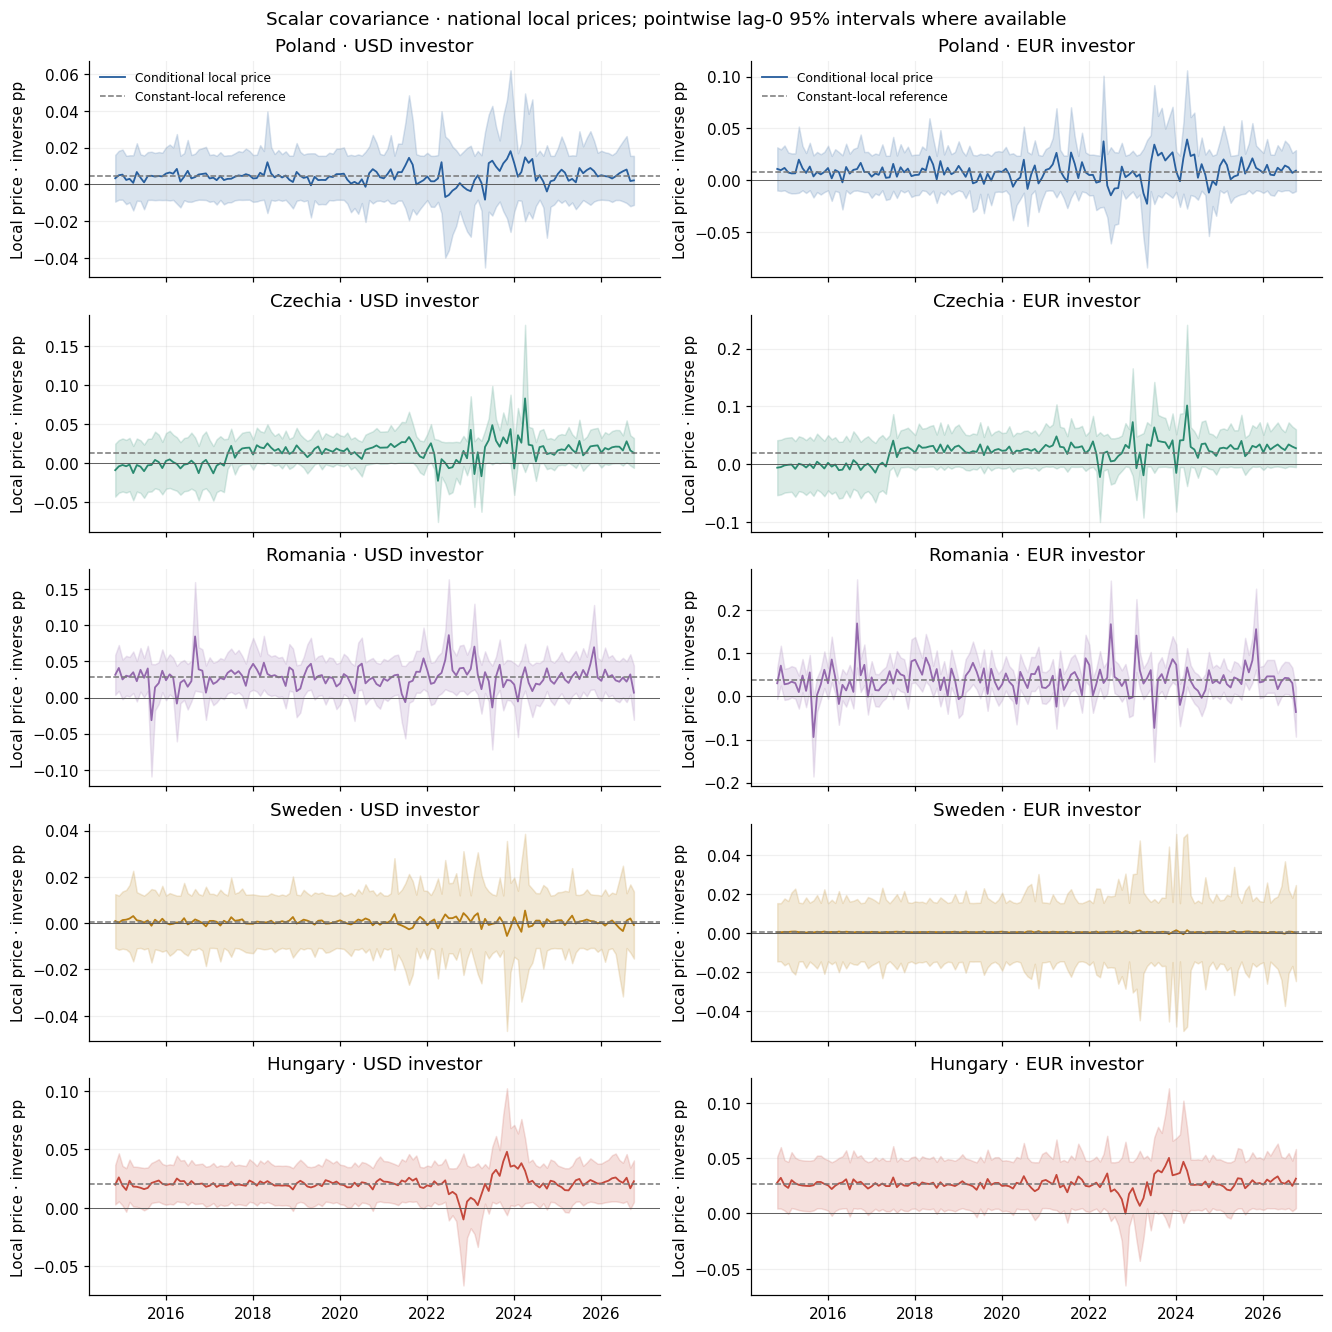

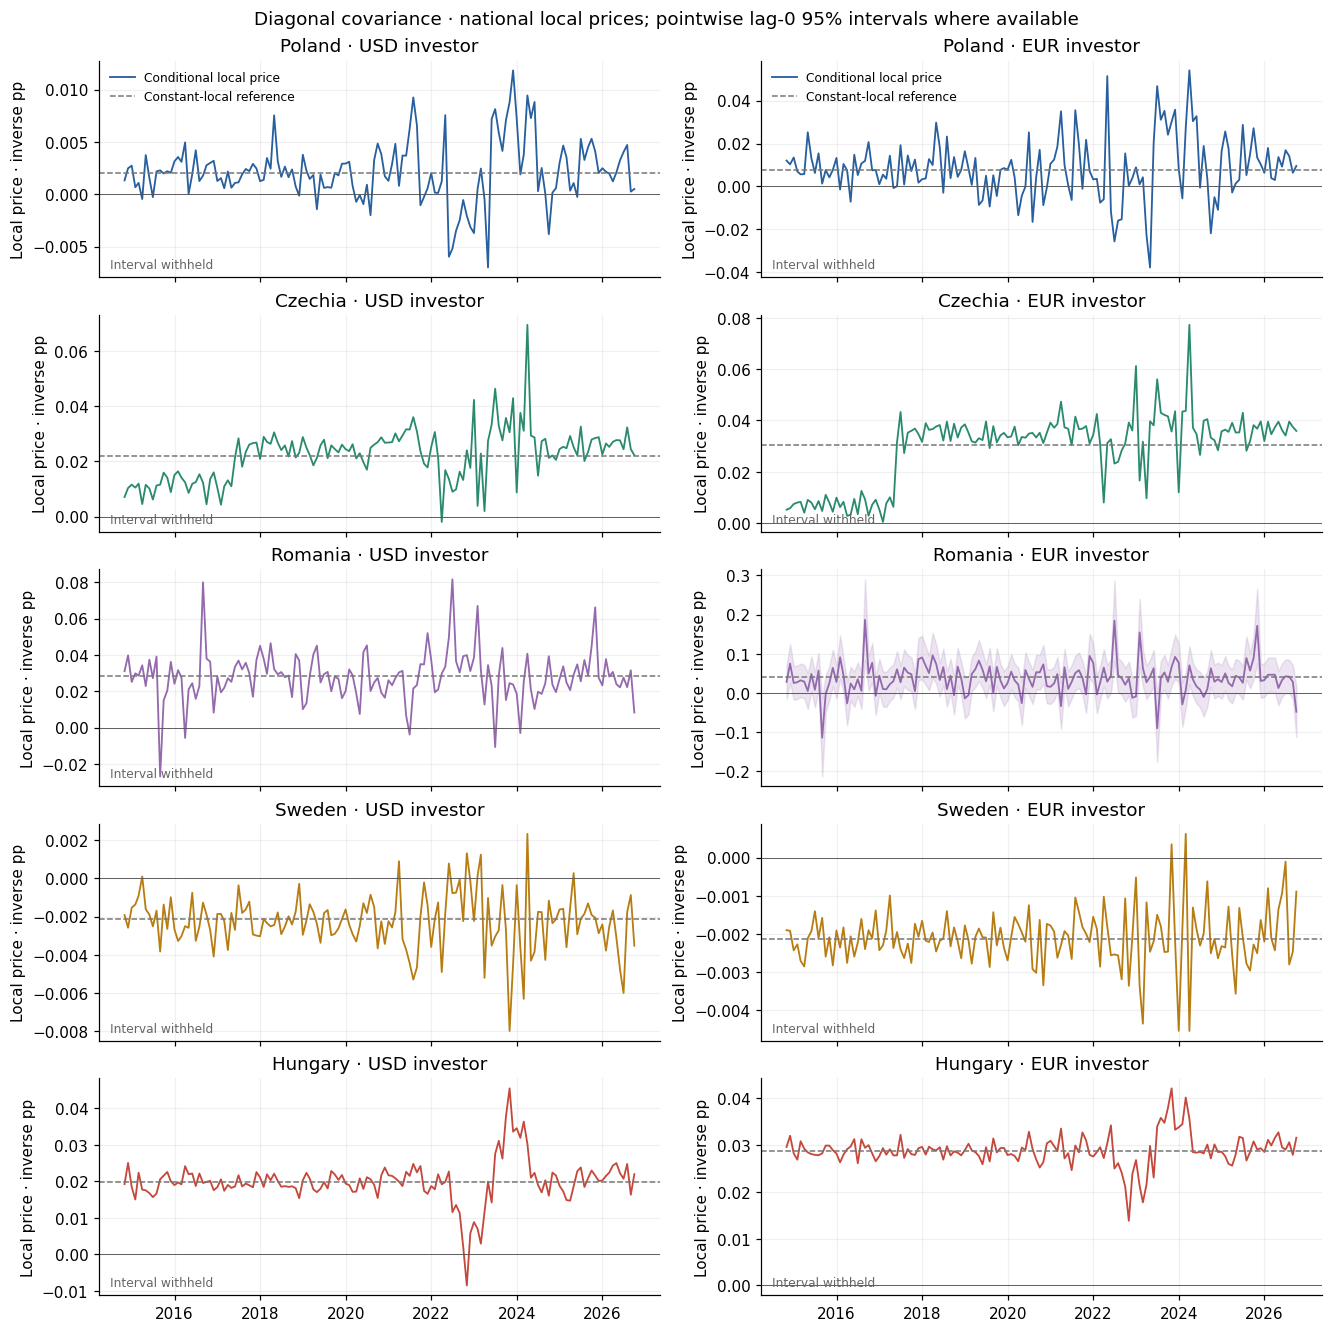

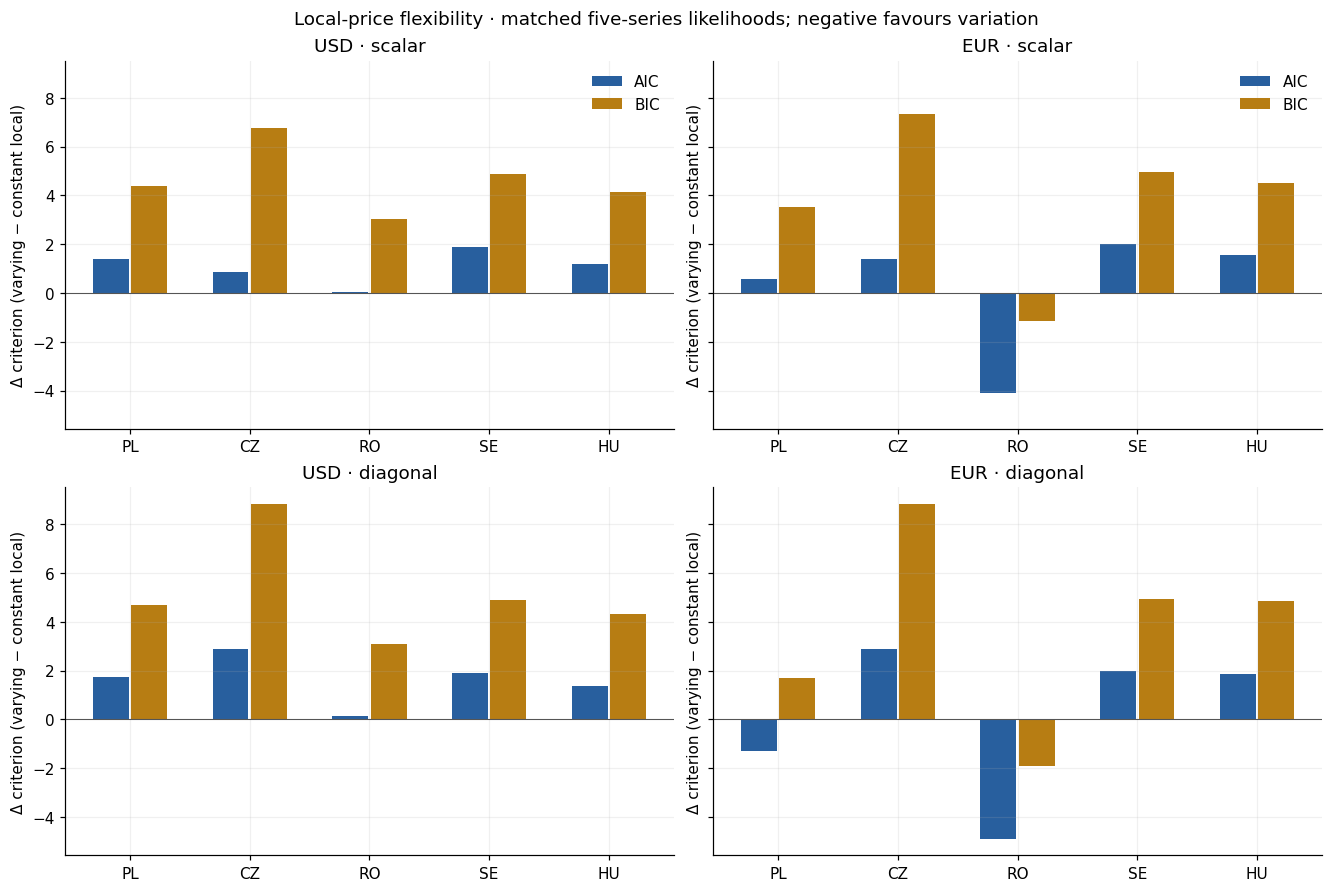

In [8]:
premium_rows, summary_rows, comparison_rows, product_rows = [], [], [], []
for (country, currency, covariance, model), fit in all_fits.items():
    f = fit["filter"]
    prices = {"world": f["world_prices"], "national_FX": f["fx_prices"][:, 0], "other_FX": f["fx_prices"][:, 1], "local": f["local_prices"]}
    covs = {"world": f["H"][:, 2, 0], "national_FX": f["H"][:, 2, 3], "other_FX": f["H"][:, 2, 4], "local": f["H"][:, 2, 2]}
    components = {risk: prices[risk]*covs[risk] for risk in prices}
    total = sum(components.values())
    np.testing.assert_allclose(total, f["mu"][:, 2], atol=1e-11, rtol=0)
    for risk, index in [("world", 0), ("national_FX", 3), ("other_FX", 4), ("local", 2)]:
        np.testing.assert_allclose(prices[risk].mean(), engine.PRICE_SCALE*fit["theta"][index], atol=1e-12, rtol=0)
    tags = {"country": country, "perspective": currency, "covariance": covariance, "model": model}
    for risk in prices:
        product_rows.append({**tags, "component": risk, "mean_risk_price": prices[risk].mean(), "mean_covariance_pp2": covs[risk].mean(),
            "mean_contribution_pp": components[risk].mean(), "product_of_means_pp": prices[risk].mean()*covs[risk].mean(),
            "price_covariance_interaction_pp": components[risk].mean()-prices[risk].mean()*covs[risk].mean(),
            "negative_price_pct": 100*np.mean(prices[risk] < 0), "negative_contribution_pct": 100*np.mean(components[risk] < 0)})
    for t, month in enumerate(months):
        premium_rows.append({**tags, "month": str(month), **{name+"_price": v[t] for name, v in prices.items()},
            **{name+"_covariance_pp2": v[t] for name, v in covs.items()}, **{name+"_premium_pp": v[t] for name, v in components.items()},
            "currency_total_pp": components["national_FX"][t]+components["other_FX"][t], "fitted_mean_pp": total[t]})
    if model != "time_varying_local": continue
    same = fit_table.query("country == @country and perspective == @currency and covariance == @covariance").set_index("model")
    choose = lambda name, lag: tests.loc[(tests.country == country) & (tests.perspective == currency) & (tests.covariance == covariance)
        & (tests.model == model) & (tests.restriction == name) & (tests.HAC_lag == lag), "p_value"].iloc[0]
    r = residuals.query("country == @country and perspective == @currency and covariance == @covariance and model == 'time_varying_local'")
    c = cross.query("country == @country and perspective == @currency and covariance == @covariance and model == 'time_varying_local'")
    da = same.loc[model, "AIC"]-same.loc["constant_local", "AIC"]
    db = same.loc[model, "BIC"]-same.loc["constant_local", "BIC"]
    comparison_rows.append({**tags, "delta_AIC": da, "delta_BIC": db, "loglik_gain": same.loc[model, "loglik"]-same.loc["constant_local", "loglik"],
        "added_parameters": int(same.loc[model, "parameters"]-same.loc["constant_local", "parameters"])})
    summary_rows.append({"country": country, "name": NAMES[country], "perspective": currency, "covariance": covariance, "months": len(months),
        "local_constancy_p_QML": choose("National local price constant", 0), "local_constancy_p_HAC12": choose("National local price constant", 12),
        "local_zero_p_QML": choose("National local price identically zero", 0), "FX_constancy_p_QML": choose("Both FX prices constant", 0),
        "national_FX_constancy_p_QML": choose("National FX price constant", 0), "other_FX_constancy_p_QML": choose("Other FX price constant", 0),
        "FX_joint_zero_p_QML": choose("FX prices jointly zero", 0), "delta_AIC": da, "delta_BIC": db,
        "mean_local_price": prices["local"].mean(), "local_negative_price_pct": 100*np.mean(prices["local"] < 0),
        "local_price_min": prices["local"].min(), "local_price_max": prices["local"].max(),
        "mean_national_FX_price": prices["national_FX"].mean(), "national_FX_negative_price_pct": 100*np.mean(prices["national_FX"] < 0),
        "mean_other_FX_price": prices["other_FX"].mean(), "other_FX_negative_price_pct": 100*np.mean(prices["other_FX"] < 0),
        **{"mean_"+risk+"_premium_pp": v.mean() for risk, v in components.items()},
        "mean_currency_total_pp": (components["national_FX"]+components["other_FX"]).mean(),
        "numerical_inference_ready": fit["inference"]["estimates"][0]["ready"], "inference_reason": fit["inference"]["estimates"][0]["reason"],
        "mean_flags_holm_5pct": int(r.LB_z_p_holm.lt(.05).sum()),
        "variance_flags_holm_5pct": int((r.LB_z_squared_p_holm.lt(.05) | r.ARCH_LM_p_holm.lt(.05)).sum()),
        "cross_flags_holm_5pct": int(c.LB_product_p_holm.lt(.05).sum())})
premiums, summary, comparison, product_summary = map(pd.DataFrame, [premium_rows, summary_rows, comparison_rows, product_rows])
for covariance in COVARIANCES:
    fig, axes = plt.subplots(5, 2, figsize=(12, 12), sharex=True, layout="constrained")
    for row, country in enumerate(NAMES):
        for col, currency in enumerate(CURRENCIES):
            ax = axes[row, col]
            p = price_paths.query("country == @country and perspective == @currency and covariance == @covariance and model == 'time_varying_local' and risk == 'National local' and HAC_lag == 0")
            dates = months.to_timestamp("M")
            ax.plot(dates, p.risk_price, color=COLORS[country], lw=1.2, label="Conditional local price")
            ax.axhline(constant_fits[(country, currency, covariance)]["filter"]["prices"][2], color="#777777", ls="--", lw=1, label="Constant-local reference")
            if p.inference_ready.all(): ax.fill_between(dates, p.ci95_low, p.ci95_high, color=COLORS[country], alpha=.17)
            else: ax.text(.02, .04, "Interval withheld", transform=ax.transAxes, color="#666666", fontsize=8)
            ax.axhline(0, color="#555555", lw=.6)
            ax.set(title=f"{NAMES[country]} · {currency} investor", ylabel="Local price · inverse pp")
            if row == 0: ax.legend(frameon=False, fontsize=8)
    fig.suptitle(f"{covariance.capitalize()} covariance · national local prices; pointwise lag-0 95% intervals where available")
    save_plot(f"02_local_prices_{covariance}.png")
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True, layout="constrained")
for row, covariance in enumerate(COVARIANCES):
    for col, currency in enumerate(CURRENCIES):
        ax = axes[row, col]
        p = comparison.query("perspective == @currency and covariance == @covariance").set_index("country").loc[list(NAMES)]
        x = np.arange(5)
        ax.bar(x-.16, p.delta_AIC, width=.3, color="#285f9e", label="AIC")
        ax.bar(x+.16, p.delta_BIC, width=.3, color="#b77d13", label="BIC")
        ax.axhline(0, color="#555555", lw=.7)
        ax.set(xticks=x, xticklabels=list(NAMES), title=f"{currency} · {covariance}", ylabel="Δ criterion (varying − constant local)")
        if row == 0: ax.legend(frameon=False)
fig.suptitle("Local-price flexibility · matched five-series likelihoods; negative favours variation")
save_plot("03_model_comparison.png")

## 8. Final common-sample comparison and reproducibility

Compare all countries with Hungary on the same 144 months. Separate model-selection criteria,
pricing-test significance, numerical stability and residual adequacy. Full-rank instruments and
mean loadings do not guarantee reliable joint inference. Keep the carried-US observation, persistent
gap-level alternative, crisis leverage and inherited diagonal instability explicit for robustness work.

The next stages are pricing-error intercept tests, consistent final model comparisons and regional
robustness/synthesis. Any hedged-versus-unhedged extension still requires explicit hedged returns,
forward/carry costs and comparable investable exposures.

In [9]:
display(summary.set_index(["name", "perspective", "covariance"])[["local_constancy_p_QML", "local_constancy_p_HAC12", "delta_AIC", "delta_BIC",
    "mean_local_price", "mean_local_premium_pp", "mean_currency_total_pp", "numerical_inference_ready"]].round(5))
display(summary.set_index(["name", "perspective", "covariance"])[["inference_reason", "mean_flags_holm_5pct", "variance_flags_holm_5pct", "cross_flags_holm_5pct"]])
tables = {"input_audit.csv": input_audit, "inflation_instrument_audit.csv": audit, "regime_audit.csv": regimes,
    "design_audit.csv": design_audit, "instrument_transform.csv": transform_table, "conditioning_design.csv": conditioning,
    "instrument_VIF.csv": vifs, "instrument_leverage.csv": leverages, "inflation_candidates.csv": candidates, "inflation_quality_flags.csv": quality_flags,
    "implementation_checks.csv": checks, "mean_loading_audit.csv": mean_loading_audit, "starting_points.csv": starts_table, "fit_summary.csv": fit_table,
    "price_coefficients.csv": coefficients, "restriction_tests.csv": tests, "inference_audit.csv": inference_audit,
    "parameter_bounds.csv": boundary_audit, "risk_price_paths.csv": price_paths, "residual_diagnostics.csv": residuals,
    "cross_covariance_diagnostics.csv": cross, "premium_components.csv": premiums, "price_covariance_products.csv": product_summary,
    "model_comparison.csv": comparison, "common_comparison.csv": summary}
for name, frame in tables.items(): frame.to_csv(OUT/name, index=False, float_format="%.17g", lineterminator="\n")
parameter_files = []
for (country, currency, covariance, model), fit in all_fits.items():
    name = f"parameters_{country}_{currency}_{covariance}_{model}.npz"
    f = fit["filter"]
    np.savez(OUT/name, theta=fit["theta"], H=f["H"], mu=f["mu"], errors=f["errors"], scores=f["scores"], target=f["target"], intercept=f["intercept"],
        Hessian=fit["inference"]["Hessian"], **{f"covariance_HAC{h}": e["covariance"] for h, e in fit["inference"]["estimates"].items()})
    parameter_files.append(name)
_, after_hashes = verify_inputs()
assert input_hashes == after_hashes and engine_hashes == {name: sha((ROOT/name).read_bytes()) for name in engine_hashes}
outputs = [*tables, *figure_files, *parameter_files]+[f"fit_{c}_{p}_{v}_time_varying_local.json" for c, p, v in fits]
metadata = {"notebook": "26_regional_time_varying_local.ipynb", "model_version": MODEL_VERSION, "engines": engine_hashes,
    "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA, "first": str(months[0]), "last": str(months[-1]), "observations_per_fit": len(months),
    "estimated_fits": len(fits), "constant_local_reference_fits": len(constant_fits), "input_locks": LOCK_HASHES, "input_file_hashes": input_hashes,
    "spec": spec, "designs": design_audit.to_dict("records"), "normalizers": transform_table.to_dict("records"),
    "settings": {"START_DYNAMICS": START_DYNAMICS, "MAX_ITER": MAX_ITER, "TEST_LAGS": TEST_LAGS, "HAC_LAGS": HAC_LAGS},
    "python": sys.executable, "python_version": platform.python_version(), "packages": versions,
    "outputs": {name: sha((OUT/name).read_bytes()) for name in outputs},
    "notes": ["Frozen common 144 months; national local price linear in audited lagged inflation-gap and varying regime conditioners",
        "World and both FX designs identical to notebook 25; all free parameters jointly re-estimated; US local price constant",
        "Corrected five priced means; zero alphas; scalar and diagonal covariance retained",
        "Raw inflation reconstruction before sample trim; inherited annual-US-inflation carry explicitly flagged; no market-data filling",
        "Only varying regime columns included; fixed-covariance mean-loading rank screened; invalid inference suppressed",
        "Fixed QML/HAC 0/3/6/12; pointwise price intervals; exploratory pricing tests unadjusted",
        "Premium means are means of monthly price-covariance products, not products of means"]}
(OUT/"estimation_manifest.json").write_text(json.dumps(metadata, indent=2, sort_keys=True)+"\n")

primary = tests.query("model == 'time_varying_local' and restriction == 'National local price constant'")
count_tests = lambda lag: f"{int(primary.loc[primary.HAC_lag.eq(lag), 'p_value'].lt(.05).sum())}/{int(primary.loc[primary.HAC_lag.eq(lag), 'p_value'].notna().sum())}"
ready_counts = summary.groupby("covariance").numerical_inference_ready.agg(["sum", "size"])
readiness = "; ".join(f"{cov}: {int(row['sum'])}/{int(row['size'])}" for cov, row in ready_counts.iterrows())
display(Markdown(f"**Reading this run:** AIC favours time-varying local prices in **{int(summary.delta_AIC.lt(0).sum())}/20** systems; "
    f"BIC favours constant local prices in **{int(summary.delta_BIC.gt(0).sum())}/20**. "
    f"The local-constancy test rejects at an unadjusted 5% level in **{count_tests(0)}** available lag-0 tests and "
    f"**{count_tests(12)}** available lag-12 tests. This bandwidth sensitivity needs robustness work before a general pricing claim.\n\n"
    f"**Primary inference available:** {readiness}. Unavailable tests/intervals remain withheld; inspect the recorded numerical reasons. "
    "Compare these pricing tests separately from model-selection criteria and residual adequacy."))

unready = int((~summary.numerical_inference_ready).sum())
display(Markdown(f"**Completed:** {len(fits)} conditional-local fits against {len(constant_fits)} verified constant-local references, "
    f"all on **{months[0]}–{months[-1]} ({len(months)} months)** in base. **{unready}/20** new systems have suppressed primary inference. "
    f"Saved {len(tables)} tables and {len(figure_files)} charts in `{OUT.relative_to(ROOT)}`. All frozen data and prior outputs remain unchanged."))

local_constancy_p_QML  \
name    perspective covariance                          
Hungary USD         scalar                    0.28144   
                    diagonal                      NaN   
        EUR         scalar                    0.40836   
                    diagonal                      NaN   
Poland  USD         scalar                    0.49985   
                    diagonal                      NaN   
        EUR         scalar                    0.31907   
                    diagonal                      NaN   
Czechia USD         scalar                    0.19886   
                    diagonal                      NaN   
        EUR         scalar                    0.36773   
                    diagonal                      NaN   
Romania USD         scalar                    0.11142   
                    diagonal                      NaN   
        EUR         scalar                    0.00404   
                    diagonal                  0.00133   
Sweden  USD         scalar                    0.76037   
                    diagonal                      NaN   
        EUR         scalar                    0.96612   
                    diagonal                      NaN   

                                local_constancy_p_HAC12  delta_AIC  delta_BIC  \
name    perspective covariance                                                  
Hungary USD         scalar                      0.25564    1.17554    4.14535   
                    diagonal                        NaN    1.35673    4.32654   
        EUR         scalar                      0.45569    1.55231    4.52212   
                    diagonal                        NaN    1.87127    4.84108   
Poland  USD         scalar                      0.26203    1.39934    4.36916   
                    diagonal                        NaN    1.72020    4.69001   
        EUR         scalar                      0.04528    0.57704    3.54685   
                    diagonal                        NaN   -1.27728    1.69254   
Czechia USD         scalar                      0.04135    0.84458    6.78420   
                    diagonal                        NaN    2.87518    8.81480   
        EUR         scalar                      0.14769    1.39863    7.33826   
                    diagonal                        NaN    2.90557    8.84519   
Romania USD         scalar                      0.14968    0.04974    3.01956   
                    diagonal                        NaN    0.13572    3.10554   
        EUR         scalar                      0.01196   -4.10454   -1.13473   
                    diagonal                    0.00924   -4.88200   -1.91218   
Sweden  USD         scalar                      0.67700    1.90728    4.87710   
                    diagonal                        NaN    1.92210    4.89191   
        EUR         scalar                      0.96500    1.99825    4.96806   
                    diagonal                        NaN    1.98769    4.95750   

                                mean_local_price  mean_local_premium_pp  \
name    perspective covariance                                            
Hungary USD         scalar               0.02054                0.95753   
                    diagonal             0.01992                0.91590   
        EUR         scalar               0.02681                0.99685   
                    diagonal             0.02892                1.07593   
Poland  USD         scalar               0.00448                0.21150   
                    diagonal             0.00216                0.10795   
        EUR         scalar               0.00840                0.27361   
                    diagonal             0.00861                0.26117   
Czechia USD         scalar               0.01310                0.39287   
                    diagonal             0.02218                0.60570   
        EUR         scalar               0.02032                0.44497   
                   

inference_reason  \
name    perspective covariance                                               
Hungary USD         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   
        EUR         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   
Poland  USD         scalar                               numerically ready   
                    diagonal                               parameter bound   
        EUR         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   
Czechia USD         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   
        EUR         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   
Romania USD         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   
        EUR         scalar                               numerically ready   
                    diagonal                             numerically ready   
Sweden  USD         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   
        EUR         scalar                               numerically ready   
                    diagonal                     ill-conditioned curvature   

                                mean_flags_holm_5pct  \
name    perspective covariance                         
Hungary USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Poland  USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Czechia USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Romania USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Sweden  USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   

                                variance_flags_holm_5pct  \
name    perspective covariance                             
Hungary USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Poland  USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Czechia USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Romania USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Sweden  USD         scalar  

**Reading this run:** AIC favours time-varying local prices in **3/20** systems; BIC favours constant local prices in **18/20**. The local-constancy test rejects at an unadjusted 5% level in **2/11** available lag-0 tests and **4/11** available lag-12 tests. This bandwidth sensitivity needs robustness work before a general pricing claim.

**Primary inference available:** diagonal: 1/10; scalar: 10/10. Unavailable tests/intervals remain withheld; inspect the recorded numerical reasons. Compare these pricing tests separately from model-selection criteria and residual adequacy.

**Completed:** 20 conditional-local fits against 20 verified constant-local references, all on **2014-10–2026-09 (144 months)** in base. **9/20** new systems have suppressed primary inference. Saved 25 tables and 4 charts in `output/26_regional_time_varying_local/2014-10_2026-09/local_19bcb384`. All frozen data and prior outputs remain unchanged.